# Análisis comparativo - Chubut (oct 2021 - ene 2022) y Jujuy (jun - ago 2023)

**Objetivo**: Contrastar dos ciclos de protesta en Argentina a partir de una base de eventos codificados desde noticias. El análisis se organiza en cinco bloque:

1. **Estructura del corpus**: tamaño, distribución temporal y geográfica.
2. **Repertorios y actores**: qué se hizo, quiénes lo hicieron.
3. **Demandas**: qué se reclamó y cómo se articuló.
4. **Intervención estatal**: cómo respondió el Estado y con qué intensidad.
5. **Contexto del conflicto**: escala, intensidad, disrupción, amenaza política y resultado.

**Autor**: Federico Nicolás Llanes

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('../data/processed/eventos_chubut_jujuy.xlsx')

df["noticia_id"] = df["noticia_id"].astype(str)
df["mes"] = df["noticia_id"].str[:6]

df["escala"] = df["escala"].astype(str).str.lower().str.strip().replace({
    "alta": "alta", "media": "media", "baja": "baja",
    "muy alta": "muy_alta",
    "no especificado": "99", "sin datos": "99",
    "nan": "99", "99.0": "99", "no aplica": "99"
})

df["intensidad"] = df["intensidad"].astype(str).str.lower().str.strip().replace({
    "alta": "alta", "media": "media", "baja": "baja",
    "muy alta": "muy_alta",
    "no especificado": "99", "sin datos": "99",
    "nan": "99", "99.0": "99"
})

# Definiciones de bloques de columnas
COLS_ACTORES = ["docentes", "gremios_estatales", "sindicatos_privados",
                "organizaciones_sociales", "comunidades_indigenas", "vecinos",
                "colectivos_ambientales", "colectivos_especificos",
                "partidos_politicos", "policias_actores",
                "publico_general", "colectivos_violentos", "otros"]

COLS_ACCION = ["tiene_marcha", "tiene_corte", "tiene_paro", "tiene_acto",
               "tiene_escrache", "tiene_destrozos", "tiene_toma"]

COLS_DEMANDAS = ["demanda_salarial", "demanda_laboral", "demanda_ambiental_territorial",
                 "demanda_politica_legal", "demanda_ddhh", "demanda_servicios",
                 "demanda_derechos_especificos", "demanda_institucional",
                 "demanda_conmemoracion"]

# Armonización de intervención estatal
def armonizar(row):
    prov = row["provincia"]
    cod = row["tipo_intervencion_estatal"]
    if pd.isna(cod): return "Sin datos"
    cod = int(cod)
    if cod == 0: return "Ausencia"
    elif cod == 1: return "Monitoreo"
    elif cod == 2: return "Contención"
    elif cod == 3: return "Represión" if prov == "Chubut" else "Disuasión"
    elif cod == 4: return "Represión"
    else: return "Sin datos"

df["intervencion_armonizada"] = df.apply(armonizar, axis=1)
df["es_represion"] = (df["intervencion_armonizada"] == "Represión").astype(int)

# Densidad del evento
df["n_actores"] = df[COLS_ACTORES].sum(axis=1)
df["n_demandas"] = df[COLS_DEMANDAS].sum(axis=1)
df["n_tipos_accion"] = df[COLS_ACCION].sum(axis=1)

df_ch = df[df["provincia"] == "Chubut"].copy()
df_j  = df[df["provincia"] == "Jujuy"].copy()

print(f"Chubut: {len(df_ch)} eventos | Jujuy: {len(df_j)} eventos")

Chubut: 121 eventos | Jujuy: 66 eventos


## Bloque 1 - Estructura del corpus

Antes de comparar contenidos, hay que comparar los contenendores. Los dos corpus tienen tamaños, ventanas temporales y coberturas geográficas distintas. Reconoces esas diferencias es condición para que el resto del análisis no confunda artefactos del corpus con patrones del conflicto.

In [8]:
print("="*65)
print("Tamaño de los corpus")
print("="*65)

resumen = pd.DataFrame({
    "Chubut": [len(df_ch)],
    "Jujuy": [len(df_j)]
}, index=["Eventos_totales"])

print(resumen.T.to_string())

dias_ch = (pd.to_datetime(df_ch["noticia_id"].str[:8], format="%Y%m%d").max() -
           pd.to_datetime(df_ch["noticia_id"].str[:8], format="%Y%m%d").min()).days
dias_j = (pd.to_datetime(df_j["noticia_id"].str[:8], format="%Y%m%d").max() -
          pd.to_datetime(df_j["noticia_id"].str[:8], format="%Y%m%d").min()).days

print(f"\nDuracion de la ventana:")
print(f"  Chubut: {dias_ch} días ({dias_ch/30:.1f} meses)")
print(f"  Jujuy:  {dias_j} días ({dias_j/30:.1f} meses)")

print(f"\nDensidad diaria (eventos por día con actividad):")
print(f"  Chubut: {len(df_ch) / dias_ch:.2f}")
print(f"  Jujuy:  {len(df_j) / dias_j:.2f}")

Tamaño de los corpus
        Eventos_totales
Chubut              121
Jujuy                66

Duracion de la ventana:
  Chubut: 87 días (2.9 meses)
  Jujuy:  68 días (2.3 meses)

Densidad diaria (eventos por día con actividad):
  Chubut: 1.39
  Jujuy:  0.97


Chubut casi duplica en cantidad de eventos a Jujuy (121 vs 66). Sin embargo esta diferencia se atenúa cuando se compara la duración ya que la ventana de los eventos de Chubut es un 33% más larga, por lo que la densisdad diaria es más parecida de lo que sugiere el total en bruto.

DISTRIBUCIÓN MENSUAL
Eventos por mes (absoluto):
provincia  Chubut  Jujuy
mes                     
202110          1      0
202111         39      0
202112         69      0
202201         12      0
202306          0     40
202307          0     21
202308          0      5

Eventos por mes (% dentro de cada provincia):
provincia  Chubut  Jujuy
mes                     
202110        0.8    0.0
202111       32.2    0.0
202112       57.0    0.0
202201        9.9    0.0
202306        0.0   60.6
202307        0.0   31.8
202308        0.0    7.6

Chubut: mes pico = 202112 con 57.0% de los eventos

Jujuy: mes pico = 202306 con 60.6% de los eventos


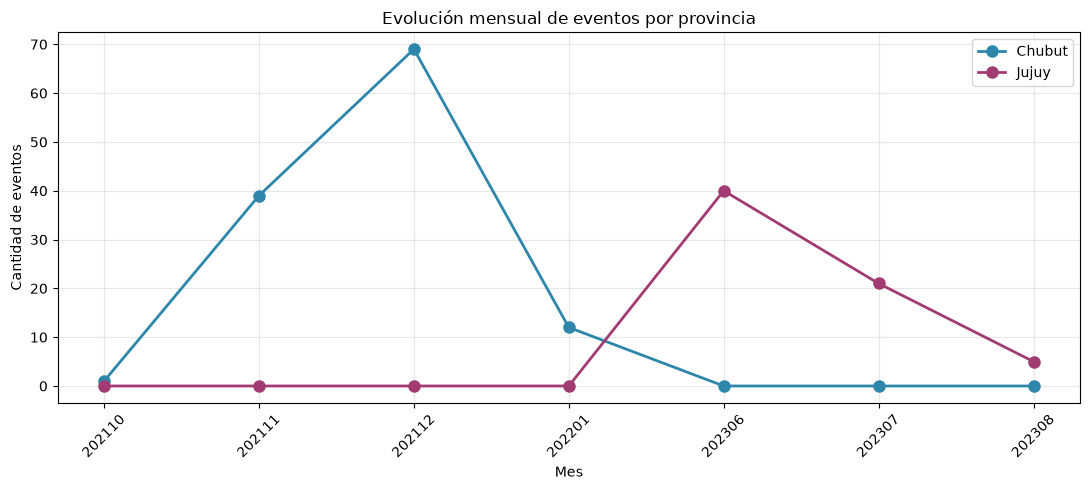

In [12]:
print("=" * 65)
print("DISTRIBUCIÓN MENSUAL")
print("=" * 65)

ct_mes = pd.crosstab(df["mes"], df["provincia"])
ct_mes_pct = pd.crosstab(df["mes"], df["provincia"], normalize="columns") * 100

print("Eventos por mes (absoluto):")
print(ct_mes.to_string())
print("\nEventos por mes (% dentro de cada provincia):")
print(ct_mes_pct.round(1).to_string())

# Concentración del mes pico
for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    pico = sub["mes"].value_counts().idxmax()
    pct = 100 * sub["mes"].value_counts().max() / len(sub)
    print(f"\n{prov}: mes pico = {pico} con {pct:.1f}% de los eventos")

fig, ax = plt.subplots(figsize=(11, 5))

for prov, color in [("Chubut", "#2E86AB"), ("Jujuy", "#A23B72")]:
    ax.plot(ct_mes.index, ct_mes[prov], marker="o", linewidth=2,
            markersize=8, color=color, label=prov)

ax.set_title("Evolución mensual de eventos por provincia")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad de eventos")
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Ambos conflictos tienen un mes dominante, pero con pesos distintos:

- En **Chubut** el mes de Diciembre de 2021 concentra el 57% de los eventos.
- En **Jujuy** el mes de Junio de 2023 concentra el 61% de los eventos.

In [14]:
print("=" * 65)
print("DISTRIBUCIÓN GEOGRÁFICA")
print("=" * 65)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    print(f"\n--- {prov} ---")
    top = sub["localidad"].value_counts().head(8)
    pct = (100 * top / len(sub)).round(1)
    print(pd.DataFrame({"n": top, "%": pct}).to_string())

# Índice de concentración (excluyendo categorías no puntuales)
def hhi(series):
    shares = series.value_counts(normalize=True)
    return (shares ** 2).sum()

categorias_genericas = ["No especificado", "Sin datos", "Chubut",
                        "Varias localidades", "Ruta (sin localidad puntual)"]

print("\n" + "=" * 65)
print("ÍNDICE DE CONCENTRACIÓN GEOGRÁFICA (HHI)")
print("=" * 65)
for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    sub_clean = sub[~sub["localidad"].isin(categorias_genericas)]
    if len(sub_clean) > 0:
        h = hhi(sub_clean["localidad"])
        print(f"{prov}: HHI = {h:.3f} (n = {len(sub_clean)})")

DISTRIBUCIÓN GEOGRÁFICA

--- Chubut ---
                  n     %
localidad                
Rawson           26  21.5
Trelew           25  20.7
Chubut           16  13.2
Esquel           16  13.2
No especificado  10   8.3
Puerto Madryn     8   6.6
Madryn            5   4.1
El Bolsón         3   2.5

--- Jujuy ---
                                n     %
localidad                              
San Salvador de Jujuy          34  51.5
Varias localidades             19  28.8
Libertador General San Martín   2   3.0
Tilcara                         2   3.0
Abra Pampa                      1   1.5
Purmamarca                      1   1.5
San Pedro de Jujuy              1   1.5
Ruta (sin localidad puntual)    1   1.5

ÍNDICE DE CONCENTRACIÓN GEOGRÁFICA (HHI)
Chubut: HHI = 0.185 (n = 95)
Jujuy: HHI = 0.578 (n = 45)


La estrucutra geográfica es radicalmente distinta.

**Chubut** tiene un patrón multi-céntrico ya que tiene cuatro ciudades con peros relevante (Rawson, Trelew, Esquel, Puerto madryn), El HHI es bajo, indicando dispersión geográfica. La caterogría "Chubut" (16 eventos) refleja limitaciones de la fuente.

**Jujuy** tiene un patrón dual: la capital concentra el 52% de los eventos, y "Varias localidades" concentra el 29%. Esta segunda categoría no es una limitación de la fuente, sino un dato del conflicto: **el 29% de los eventos jujeños fueron acciones simultáneas en múltiples puntos**, principalmente cortes coordinados en rutas provinciales.

En Chubut el conflicto se expresó como movilizaciones en distintas ciudades con dinámicas propias. En Jujuy el conflicto se organizó como una estrategia provincial con dos brazos: movilización urbana en la capital y acción territorial coordinada en el interior.

## Bloque 2 - Repertorios y actores

Este bloque compara qué se hizo (repertorios) y quiénes lo hicieron (actores). Las comparaciones son relativas: cada porcentaje está calculado sobre el total de la provincia, no sobre el total combinado.

REPERTORIOS: % de eventos por tipo de acción
                 Chubut  Jujuy  diferencia
tiene_paro          8.3   21.2        12.9
tiene_corte        10.7   21.2        10.5
tiene_marcha       44.6   54.5         9.9
tiene_toma          2.5    0.0        -2.5
tiene_escrache      3.3    0.0        -3.3
tiene_destrozos     4.1    0.0        -4.1
tiene_acto         10.7    4.5        -6.2


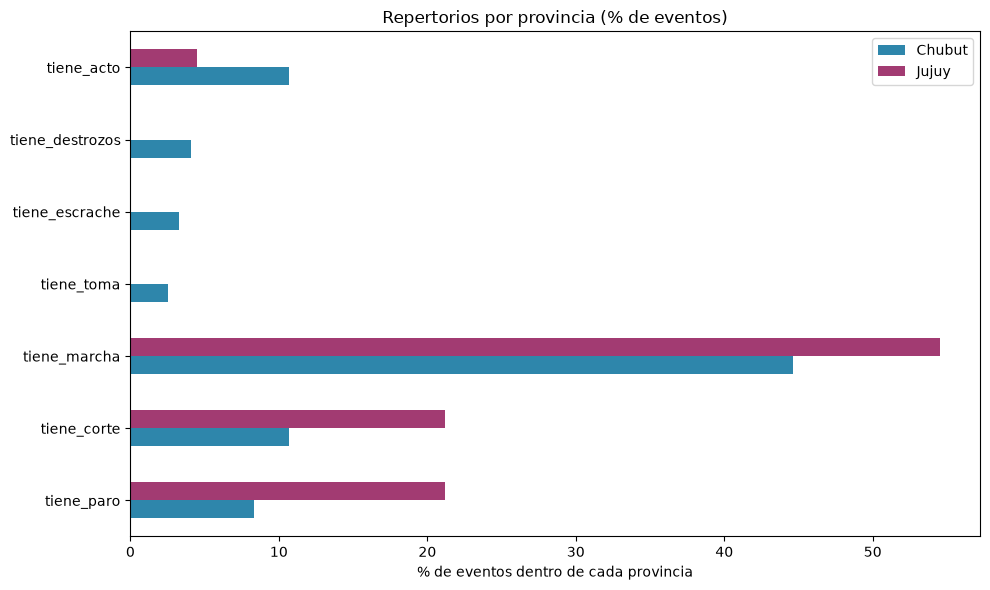

In [15]:
print("=" * 65)
print("REPERTORIOS: % de eventos por tipo de acción")
print("=" * 65)

repertorios = (df.groupby("provincia")[COLS_ACCION].mean() * 100).round(1).T
repertorios.columns = ["Chubut", "Jujuy"]
repertorios["diferencia"] = (repertorios["Jujuy"] - repertorios["Chubut"]).round(1)
repertorios = repertorios.sort_values("diferencia", ascending=False)

print(repertorios.to_string())

# Gráfico
fig, ax = plt.subplots(figsize=(10, 6))
repertorios[["Chubut", "Jujuy"]].plot(kind="barh", ax=ax,
                                       color=["#2E86AB", "#A23B72"])
ax.set_title("Repertorios por provincia (% de eventos)")
ax.set_xlabel("% de eventos dentro de cada provincia")
plt.tight_layout()
plt.show()

ACTORES: % de eventos con cada actor
                         Chubut  Jujuy  diferencia
docentes                    1.7   62.1        60.4
organizaciones_sociales     4.1   30.3        26.2
comunidades_indigenas       5.0   27.3        22.3
gremios_estatales          14.9   19.7         4.8
colectivos_especificos      1.7    4.5         2.8
otros                       0.8    0.0        -0.8
partidos_politicos          4.1    1.5        -2.6
publico_general            10.7    7.6        -3.1
sindicatos_privados        11.6    7.6        -4.0
vecinos                    20.7   16.7        -4.0
colectivos_violentos        5.0    0.0        -5.0
policias_actores            7.4    0.0        -7.4
colectivos_ambientales     13.2    0.0       -13.2


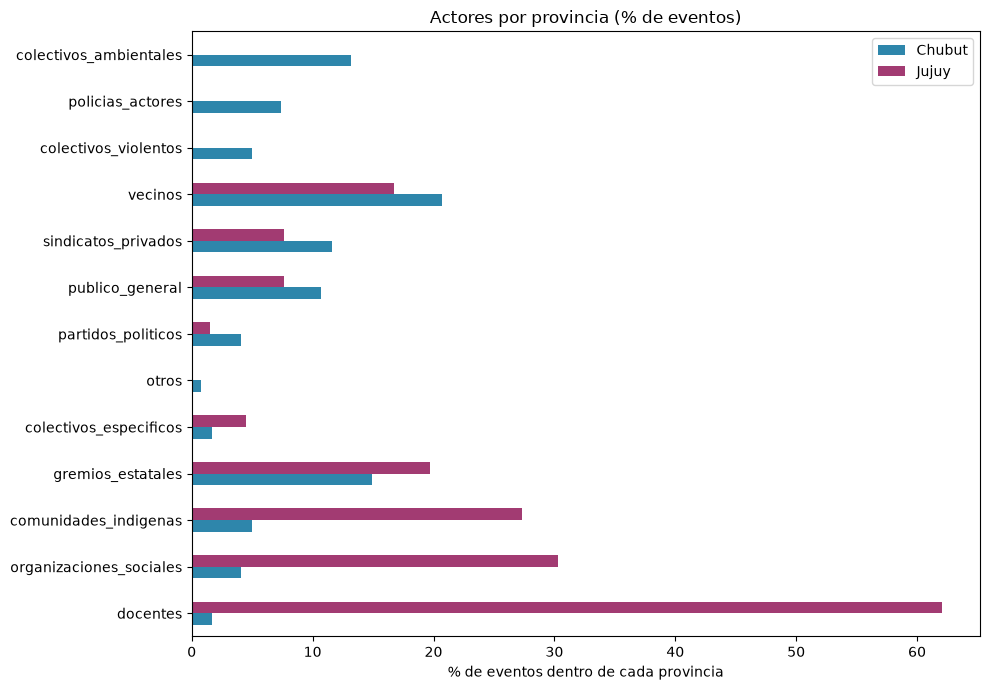

In [16]:
print("=" * 65)
print("ACTORES: % de eventos con cada actor")
print("=" * 65)

actores = (df.groupby("provincia")[COLS_ACTORES].mean() * 100).round(1).T
actores.columns = ["Chubut", "Jujuy"]
actores["diferencia"] = (actores["Jujuy"] - actores["Chubut"]).round(1)
actores = actores.sort_values("diferencia", ascending=False)

print(actores.to_string())

# Gráfico
fig, ax = plt.subplots(figsize=(10, 7))
actores[["Chubut", "Jujuy"]].plot(kind="barh", ax=ax,
                                   color=["#2E86AB", "#A23B72"])
ax.set_title("Actores por provincia (% de eventos)")
ax.set_xlabel("% de eventos dentro de cada provincia")
plt.tight_layout()
plt.show()

la composición de actores es el punto de mayor divergencia estructural entre ambos casos.

Jujuy tiene tres actores con peso masivo: docentes (62.1%), organizaciones sociales (30.3%) y comunidades originarias (27.3%). Los tres articulan un espacio multisectorial activo: los docentes como núcleo movilizador, las organizaciones sociales como sostén territorial y las comunidades originarias como actor protagónico en el conflicto por la reforma constitucional.

Chubut tiene un panorama más fragmentado: vecinos (20.7%), gremios estatales (14.9%), colectivos ambientales (13.2%) y sindicatos privados (11.6%). Ningún actor supera el 21%. El conflicto es territorial-ambiental pero sin un actor hegemónico que lo organice.

Los actores exclusivos refuerzan la diferencia. Chubut tiene policías como manifestantes (7.4%, protestas salariales de la fuerza) y colectivos violentos (5%, encapuchados del pico de diciembre), ambos ausentes en Jujuy. Jujuy tiene un peso de organizaciones sociales (30.3% vs 4.1%) y comunidades originarias (27.3% vs 5%) que no tiene equivalente chubutense.

La lectura comparativa es clara: **en Jujuy los actores estaban coordinados y compartían un eje común; en Chubut cada actor sostenía su reclamo de forma relativamente aislada**.

DENSIDAD DEL EVENTO
          n_actores            n_demandas            n_tipos_accion           
               mean median max       mean median max           mean median max
provincia                                                                     
Chubut         1.01    1.0   3       0.95    1.0   3           0.84    1.0   1
Jujuy          1.77    1.0   5       1.48    1.0   4           1.02    1.0   2

=== Distribución de cantidad de actores por evento ===

Chubut:
n_actores
0    16.5
1    69.4
2    10.7
3     3.3

Jujuy:
n_actores
1    54.5
2    22.7
3    15.2
4     6.1
5     1.5


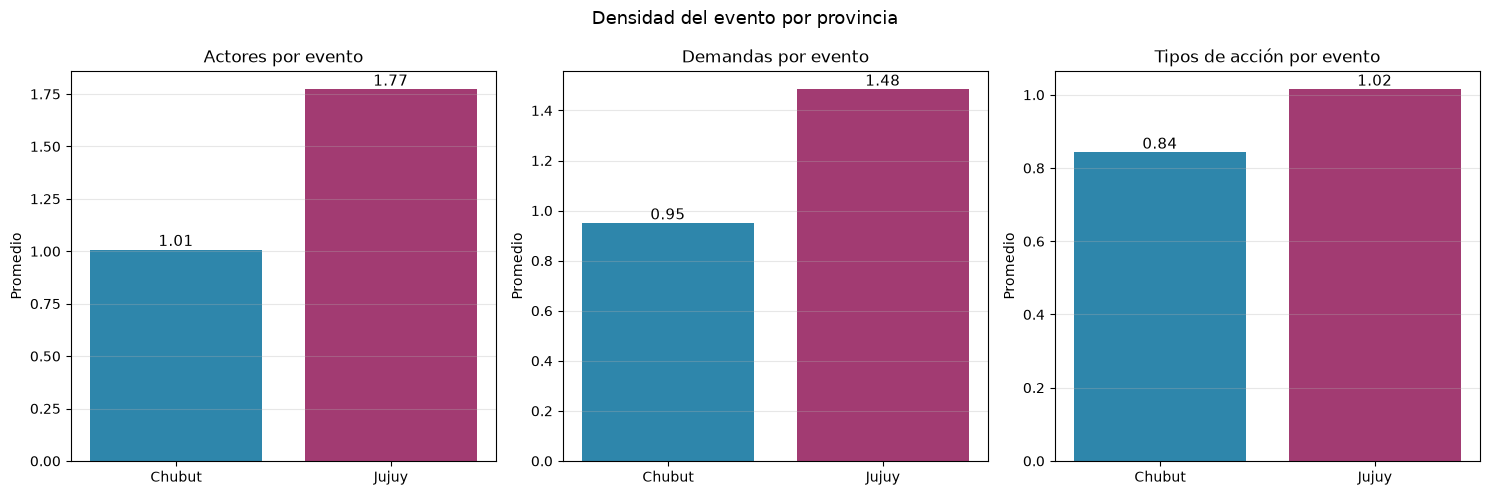

In [31]:
print("=" * 65)
print("DENSIDAD DEL EVENTO")
print("=" * 65)

resumen = df.groupby("provincia")[["n_actores", "n_demandas", "n_tipos_accion"]].agg(
    ["mean", "median", "max"]
).round(2)
print(resumen.to_string())

# Distribución de n_actores
print("\n=== Distribución de cantidad de actores por evento ===")
for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    print(f"\n{prov}:")
    print((100 * sub["n_actores"].value_counts(normalize=True).sort_index()).round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metricas = [
    ("n_actores", "Actores por evento"),
    ("n_demandas", "Demandas por evento"),
    ("n_tipos_accion", "Tipos de acción por evento"),
]

for ax, (col, titulo) in zip(axes, metricas):
    medias = df.groupby("provincia")[col].mean()
    ax.bar(medias.index, medias.values, color=["#2E86AB", "#A23B72"])
    for i, v in enumerate(medias.values):
        ax.annotate(f"{v:.2f}", (i, v), ha="center", va="bottom", fontsize=11)
    ax.set_title(titulo)
    ax.set_ylabel("Promedio")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Densidad del evento por provincia", fontsize=13)
plt.tight_layout()
plt.show()

Los eventos jujeños son estructuralmente más densos que los chubutenses:

- Demandas por evento: 1.48 vs 0.95 (Jujuy un 56% más alto)
- Actores por evento: 1.77 vs 1.01 (Jujuy un 75% más alto)
- Tipos de acción por evento: 1.02 vs 0.84

La diferencia no está en el promedio sino en la forma de la distribución. En Chubut, el 69.4% de los eventos tienen un solo actor; los eventos con dos actores apenas llegan al 10.7% y con tres al 3.3%. En Jujuy, los eventos con un solo actor son el 54.5%; los de dos actores son el 22.7% y los de tres o más suman el 22.8%.

Esto configura dos lógicas distintas de organización de la protesta. **Chubut como conflicto de agregación**: muchos eventos simples convocados por actores específicos, cuya conflictividad emerge de la acumulación. **Jujuy como conflicto de articulación**: menos eventos pero más densos, con capacidad de coordinar múltiples actores, demandas y repertorios en un mismo episodio.

## Bloque 3 — Demandas

Se comparan las demandas por frecuencia relativa y por articulación (cuántas demandas se superponen en un mismo evento). Los EDA mostraron que la distribución interna de demandas es distinta en cada provincia; acá se mide cuánto difiere.

DEMANDAS: % de eventos con cada demanda
                               Chubut  Jujuy  diferencia
demanda_politica_legal           10.7   59.1        48.4
demanda_salarial                 23.1   59.1        36.0
demanda_conmemoracion             0.0    4.5         4.5
demanda_ddhh                      9.9   12.1         2.2
demanda_derechos_especificos      4.1    4.5         0.4
demanda_laboral                   6.6    4.5        -2.1
demanda_servicios                 2.5    0.0        -2.5
demanda_institucional             5.0    1.5        -3.5
demanda_ambiental_territorial    33.1    3.0       -30.1


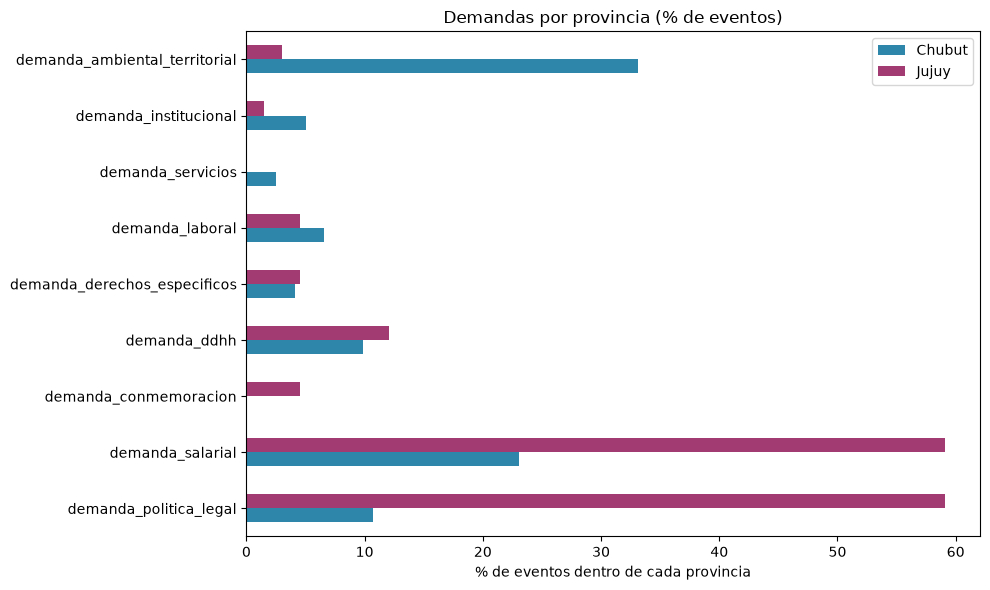

In [20]:
print("=" * 65)
print("DEMANDAS: % de eventos con cada demanda")
print("=" * 65)

demandas = (df.groupby("provincia")[COLS_DEMANDAS].mean() * 100).round(1).T
demandas.columns = ["Chubut", "Jujuy"]
demandas["diferencia"] = (demandas["Jujuy"] - demandas["Chubut"]).round(1)
demandas = demandas.sort_values("diferencia", ascending=False)

print(demandas.to_string())

# Gráfico
fig, ax = plt.subplots(figsize=(10, 6))
demandas[["Chubut", "Jujuy"]].plot(kind="barh", ax=ax,
                                    color=["#2E86AB", "#A23B72"])
ax.set_title("Demandas por provincia (% de eventos)")
ax.set_xlabel("% de eventos dentro de cada provincia")
plt.tight_layout()
plt.show()

**Jujuy articula un doble eje con igual peso**: demanda política-legal (59.1%) y demanda salarial (59.1%). Esto indica que la mayoría de los eventos combinaban ambos reclamos: la reforma constitucional (eje político) y las paritarias docentes (eje salarial).

**Chubut tiene un eje dominante con un secundario**: demanda ambiental-territorial (33.1%) y salarial (23.1%). El conflicto es principalmente anti-minero, con el eje salarial como complemento.

Las demandas con mayor diferencia son:
- **política-legal**: +48.4 puntos porcentuales a favor de Jujuy
- **salarial**: +36.0 puntos a favor de Jujuy
- **ambiental-territorial**: -30.1 puntos (Chubut muy por encima)

Esto define dos tipos de conflicto: uno **político-institucional con componente salarial** (Jujuy) vs uno **ambiental-territorial con componente salarial secundario** (Chubut).

In [21]:
print("=" * 65)
print("ARTICULACIÓN DE DEMANDAS")
print("=" * 65)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    print(f"\n--- {prov} ---")
    conteo = sub["n_demandas"].value_counts(normalize=True).sort_index() * 100
    print(conteo.round(1).to_string())

print("\n=== Promedio y desvío ===")
resumen = df.groupby("provincia")["n_demandas"].agg(["mean", "std", "median", "max"]).round(2)
print(resumen.to_string())

ARTICULACIÓN DE DEMANDAS

--- Chubut ---
n_demandas
0    22.3
1    61.2
2    15.7
3     0.8

--- Jujuy ---
n_demandas
0     9.1
1    43.9
2    37.9
3     7.6
4     1.5

=== Promedio y desvío ===
           mean   std  median  max
provincia                         
Chubut     0.95  0.64     1.0    3
Jujuy      1.48  0.83     1.0    4


**Lectura**: el grado de articulación de demandas es una diferencia cuantitativa fuerte.

En **Jujuy**, el 47% de los eventos tienen dos o más demandas. La mayoría combina el eje salarial con el político-legal. Los eventos de demanda única (44%) son todavía mayoría pero por un margen estrecho.

En **Chubut**, la distribución es más fragmentada: la mayoría de los eventos (más del 50%) tienen una sola demanda, y los eventos con dos o más demandas son minoría.

El promedio de **1.48 demandas por evento en Jujuy vs 0.95 en Chubut** es uno de los hallazgos más limpios del comparativo. Los eventos jujeños son eventos "densos" en términos de demandas; los chubutenses son eventos "puros" de reclamo único.

Esto se corresponde con la estructura de actores: Jujuy tiene actores organizados que articulan demandas múltiples; Chubut tiene actores locales que sostienen reclamos específicos.

## Bloque 4 — Intervención estatal

Este bloque compara cómo respondió el Estado en cada caso. Se incluyen las variables más densas del libro de códigos: tipo de intervención, represión específica, judicialización, heridos y detenciones. El foco está en contrastar no solo la frecuencia sino también el **blanco** de la intervención.

INTERVENCIÓN ESTATAL ARMONIZADA
intervencion_armonizada  Ausencia  Contención  Disuasión  Monitoreo  Represión  Sin datos
provincia                                                                                
Chubut                       56.2         7.4        0.0        7.4        4.1       24.8
Jujuy                        50.0         6.1        3.0       13.6        7.6       19.7


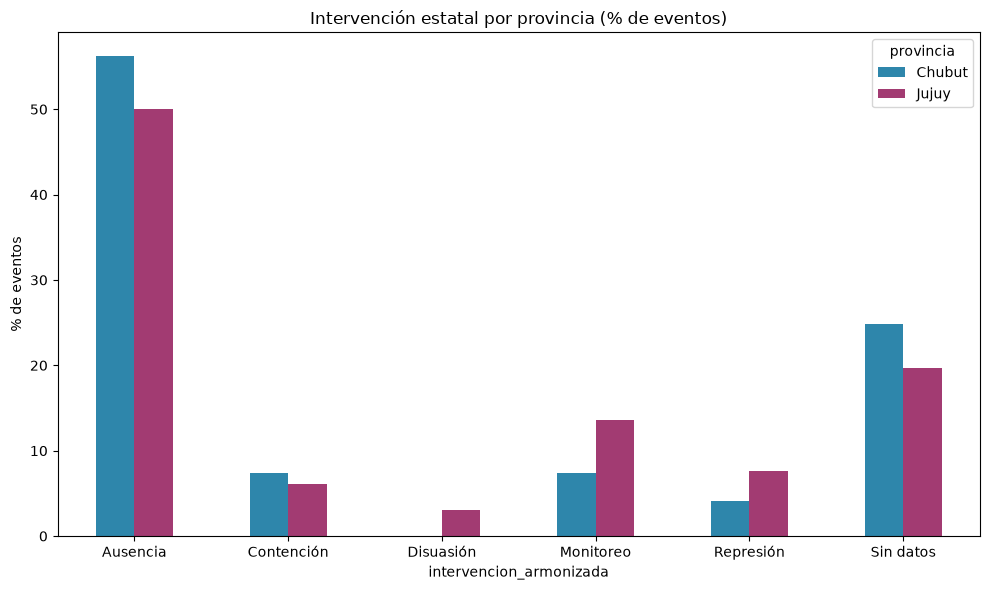

In [22]:
print("=" * 65)
print("INTERVENCIÓN ESTATAL ARMONIZADA")
print("=" * 65)

ct_int = pd.crosstab(df["provincia"], df["intervencion_armonizada"], normalize="index") * 100
ct_int = ct_int.round(1)
print(ct_int.to_string())

# Gráfico
fig, ax = plt.subplots(figsize=(10, 6))
ct_int.T.plot(kind="bar", ax=ax,
              color=["#2E86AB", "#A23B72"])
ax.set_title("Intervención estatal por provincia (% de eventos)")
ax.set_ylabel("% de eventos")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

**Lectura**: Jujuy desplegó una intervención estatal más activa que Chubut.

- **Ausencia**: 50.0% en Jujuy vs 56.2% en Chubut.
- **Monitoreo**: 13.6% vs 7.4%.
- **Contención**: 6.1% vs 7.4% (similar).
- **Disuasión**: 3.0% vs 0.0% (exclusiva de Jujuy).
- **Represión**: 7.6% vs 4.1%.
- **Sin datos**: 19.7% vs 24.8%.

El dato más fuerte es la **disuasión**: es una categoría exclusiva de Jujuy y ausente en Chubut. La disuasión implica una estrategia estatal activa de desincentivar la protesta sin recurrir a la fuerza. Su presencia en Jujuy es un indicador de la estrategia de disciplinamiento preventivo.

Chubut tiene mayor "sin datos" (24.8%), lo que sugiere que la fuente periodística cubrió menos la respuesta estatal. Esto puede reflejar tanto menor actividad estatal como menor cobertura mediática de la actividad.

**Advertencia metodológica**: los porcentajes brutos están afectados por la diferencia de cobertura. Si se calcula la tasa de represión solo sobre eventos con datos disponibles, la diferencia se amplifica: Jujuy pasa a ~9.5% y Chubut a ~5.5%.

In [23]:
print("=" * 65)
print("TASA DE REPRESIÓN: bruta vs ajustada por cobertura")
print("=" * 65)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    total = len(sub)
    con_datos = sub[sub["intervencion_armonizada"] != "Sin datos"]
    n_rep = sub["es_represion"].sum()
    tasa_bruta = 100 * n_rep / total
    tasa_ajustada = 100 * n_rep / len(con_datos) if len(con_datos) > 0 else 0
    print(f"{prov}:")
    print(f"  Total eventos: {total}")
    print(f"  Eventos con datos: {len(con_datos)} ({100*len(con_datos)/total:.1f}%)")
    print(f"  Eventos con represión: {n_rep}")
    print(f"  Tasa bruta: {tasa_bruta:.1f}%")
    print(f"  Tasa ajustada (solo con datos): {tasa_ajustada:.1f}%")
    print()

TASA DE REPRESIÓN: bruta vs ajustada por cobertura
Chubut:
  Total eventos: 121
  Eventos con datos: 91 (75.2%)
  Eventos con represión: 5
  Tasa bruta: 4.1%
  Tasa ajustada (solo con datos): 5.5%

Jujuy:
  Total eventos: 66
  Eventos con datos: 53 (80.3%)
  Eventos con represión: 5
  Tasa bruta: 7.6%
  Tasa ajustada (solo con datos): 9.4%



la tasa ajustada confirma la diferencia y la amplía. Jujuy tiene casi el doble de tasa de represión que Chubut cuando se controla por cobertura de la fuente.

Esto es importante porque desactiva un posible argumento alternativo: "Chubut tiene menos represión porque tiene menos cobertura". La tasa ajustada muestra que incluso sobre eventos con información disponible, Jujuy tiene más represión proporcional.

In [24]:
print("=" * 65)
print("JUDICIALIZACIÓN")
print("=" * 65)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    total = len(sub)
    con_datos = sub[sub["judicializacion"] != 99]
    n_jud = sub[sub["judicializacion"] == 1]
    print(f"\n--- {prov} ---")
    print(f"  Eventos judicializados: {len(n_jud)}")
    print(f"  Tasa sobre el total: {100 * len(n_jud) / total:.1f}%")
    if len(con_datos) > 0:
        print(f"  Tasa sobre eventos con datos: {100 * len(n_jud) / len(con_datos):.1f}%")
    if len(n_jud) > 0:
        print(f"  Tipo de acción de los eventos judicializados:")
        print(f"    {n_jud['tipo_accion'].value_counts().to_dict()}")

JUDICIALIZACIÓN

--- Chubut ---
  Eventos judicializados: 7
  Tasa sobre el total: 5.8%
  Tasa sobre eventos con datos: 15.2%
  Tipo de acción de los eventos judicializados:
    {'Manifestación': 3, 'Mixta': 1, 'Corte': 1, 'Marcha': 1, 'Destrozos': 1}

--- Jujuy ---
  Eventos judicializados: 5
  Tasa sobre el total: 7.6%
  Tasa sobre eventos con datos: 71.4%
  Tipo de acción de los eventos judicializados:
    {'Corte': 5}


la judicialización es baja en ambas provincias en términos absolutos, pero cualitativamente distinta y con una intensidad relativa muy desigual.

En **Chubut**, los 7 eventos judicializados se distribuyen entre tipos de acción variados: manifestación (3), mixta (1), corte (1), marcha (1), destrozos (1). La judicialización es dispersa, reactiva a distintos episodios del conflicto.

En **Jujuy**, los 5 eventos judicializados son **todos cortes**. Y el dato más fuerte es la tasa: sobre los 7 eventos con información disponible sobre judicialización, 5 terminaron judicializados. Es decir, **el 71.4% de los eventos con datos fueron judicializados**. Es una estrategia sistemática de persecución penal contra un repertorio específico.

Esta diferencia es coherente con la política estatal de cada provincia. En Jujuy la reforma constitucional buscaba penalizar los cortes de ruta; la judicialización efectiva era la aplicación natural de esa norma. En Chubut no había una política específica contra un repertorio, por lo que la judicialización fue más errática y dispersa.

In [26]:
print("=" * 70)
print("CRUCE: TIPO DE ACCIÓN × INTERVENCIÓN ESTATAL")
print("=" * 70)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    print(f"\n=== {prov} ===")
    filas = []
    for accion in COLS_ACCION:
        sub_acc = sub[sub[accion] == 1]
        n = len(sub_acc)
        if n >= 3:
            fila = {"acción": accion.replace("tiene_", ""), "n": n}
            for cat in ["Ausencia", "Monitoreo", "Contención", "Disuasión", "Represión", "Sin datos"]:
                fila[cat] = (sub_acc["intervencion_armonizada"] == cat).sum()
            filas.append(fila)
    print(pd.DataFrame(filas).set_index("acción").to_string())

CRUCE: TIPO DE ACCIÓN × INTERVENCIÓN ESTATAL

=== Chubut ===
            n  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
acción                                                                         
marcha     54        31          3           6          0          2         12
corte      13         8          2           1          0          1          1
paro       10         9          0           0          0          0          1
acto       13         9          1           0          0          1          2
escrache    4         2          0           0          0          0          2
destrozos   5         3          0           2          0          0          0
toma        3         2          1           0          0          0          0

=== Jujuy ===
         n  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
acción                                                                      
marcha  36        23          4           0       

El hallazgo más fuerte del cruce es que **el corte de ruta es el repertorio más castigado, y lo es mucho más en Jujuy que en Chubut**.

- Jujuy: de 14 cortes, 4 tuvieron represión (28.6%) y 2 tuvieron disuasión (14.3%). En total, el 42.9% de los cortes recibió algún tipo de intervención estatal activa.
- Chubut: de 13 cortes, solo 1 tuvo represión (7.7%). El 61.5% de los cortes tuvieron ausencia estatal.

Otro dato relevante: **los paros no reciben represión en ninguna de las dos provincias** (0/10 Chubut, 0/14 Jujuy). La represión se dirige a la acción en la vía pública, no a las medidas de fuerza gremial. Esto sugiere que el Estado discrimina entre repertorios: tolera el paro pero castiga el corte.

La interpretación de fondo es política: en Jujuy el corte era precisamente el objeto de la reforma constitucional, por lo que el Estado tenía un incentivo explícito para reprimirlo. En Chubut, el corte era una táctica más sin estatus de "objeto de política pública".

CRUCE: ACTOR × REPRESIÓN

=== Chubut ===
                          n  n_rep  %_rep
actor                                    
gremios_estatales        18      0    0.0
sindicatos_privados      14      2   14.3
organizaciones_sociales   5      0    0.0
comunidades_indigenas     6      0    0.0
vecinos                  25      0    0.0
colectivos_ambientales   16      3   18.8
partidos_politicos        5      1   20.0
policias_actores          9      0    0.0
publico_general          13      1    7.7
colectivos_violentos      6      0    0.0

=== Jujuy ===
                          n  n_rep  %_rep
actor                                    
docentes                 41      3    7.3
gremios_estatales        13      0    0.0
sindicatos_privados       5      0    0.0
organizaciones_sociales  20      3   15.0
comunidades_indigenas    18      5   27.8
vecinos                  11      0    0.0
colectivos_especificos    3      0    0.0
publico_general           5      1   20.0


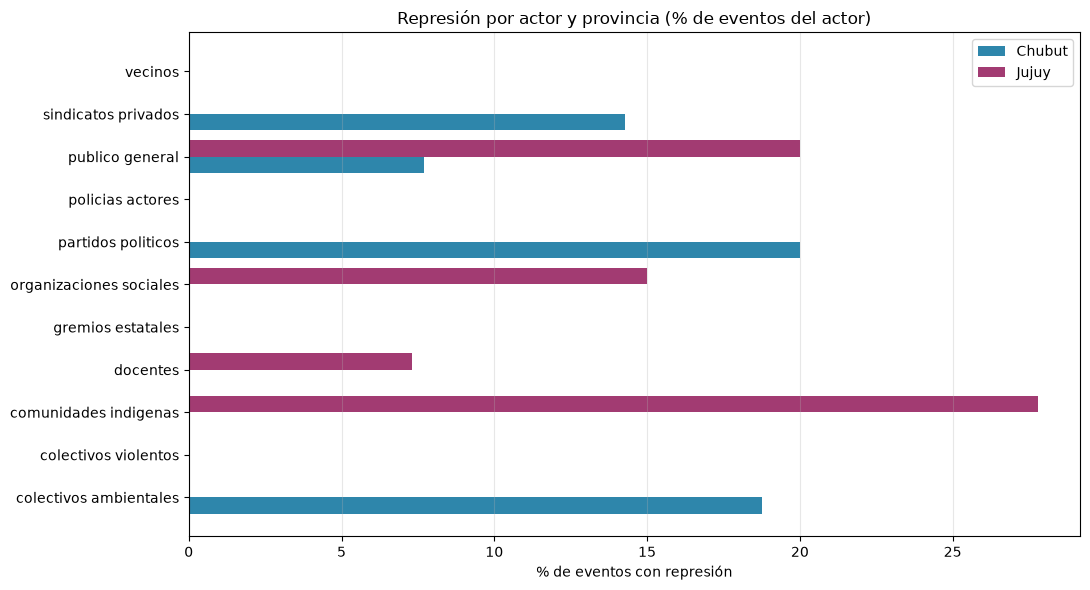

In [32]:
print("=" * 70)
print("CRUCE: ACTOR × REPRESIÓN")
print("=" * 70)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    print(f"\n=== {prov} ===")
    filas = []
    for actor in COLS_ACTORES:
        sub_act = sub[sub[actor] == 1]
        n = len(sub_act)
        if n >= 3:
            n_rep = sub_act["es_represion"].sum()
            filas.append({
                "actor": actor,
                "n": n,
                "n_rep": n_rep,
                "%_rep": round(100 * n_rep / n, 1)
            })
    print(pd.DataFrame(filas).set_index("actor").to_string())


# Construir los datos
datos_rep = []
for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    for actor in COLS_ACTORES:
        sub_act = sub[sub[actor] == 1]
        n = len(sub_act)
        if n >= 5:  # solo actores con base razonable
            n_rep = sub_act["es_represion"].sum()
            datos_rep.append({
                "provincia": prov,
                "actor": actor.replace("_", " "),
                "n": n,
                "n_rep": n_rep,
                "%_rep": 100 * n_rep / n
            })

df_rep = pd.DataFrame(datos_rep)

fig, ax = plt.subplots(figsize=(11, 6))

ch = df_rep[df_rep["provincia"] == "Chubut"].sort_values("%_rep")
ju = df_rep[df_rep["provincia"] == "Jujuy"].sort_values("%_rep")

# Combinar actores únicos
actores_todos = sorted(set(ch["actor"]) | set(ju["actor"]))
y_pos = np.arange(len(actores_todos))

# Mapear valores
ch_map = dict(zip(ch["actor"], ch["%_rep"]))
ju_map = dict(zip(ju["actor"], ju["%_rep"]))

ch_vals = [ch_map.get(a, 0) for a in actores_todos]
ju_vals = [ju_map.get(a, 0) for a in actores_todos]

ancho = 0.38
ax.barh(y_pos - ancho/2, ch_vals, ancho, label="Chubut", color="#2E86AB")
ax.barh(y_pos + ancho/2, ju_vals, ancho, label="Jujuy", color="#A23B72")

ax.set_yticks(y_pos)
ax.set_yticklabels(actores_todos)
ax.set_xlabel("% de eventos con represión")
ax.set_title("Represión por actor y provincia (% de eventos del actor)")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

El cruce actor × represión muestra quiénes fueron los blancos de la represión estatal.

**Jujuy**: las comunidades originarias fueron el actor más reprimido (27.8%, 5 de 18 eventos), seguidas por organizaciones sociales (15%) y docentes (7.3%). Este orden es significativo: a pesar de que los docentes fueron el actor más movilizado (62.1% del corpus), las comunidades originarias fueron proporcionalmente las más castigadas.

**Chubut**: los colectivos ambientales (18.8%) y partidos políticos (20%) aparecen con las tasas más altas, pero sobre bases muy pequeñas. Los sindicatos privados (14.3%, 2 de 14) son el único actor con tasa significativa y base razonable.

El patrón que emerge: en Jujuy la represión se dirigió contra los actores territorialmente más vulnerables (comunidades originarias, organizaciones sociales). En Chubut, el actor más movilizado (vecinos, 20.7%) no tuvo represión proporcional.

Esto sugiere que la represión en Jujuy fue **selectiva contra los sectores con menor capacidad de defensa legal o mediática**. Los docentes, con mayor visibilidad y respaldo gremial, fueron menos reprimidos proporcionalmente que las comunidades originarias.

CRUCE: MES × INTERVENCIÓN ESTATAL

=== Chubut ===
intervencion_armonizada  Ausencia  Monitoreo  Contención  Represión  Sin datos
mes                                                                           
202110                          0          0           0          0          1
202111                         23          6           2          1          7
202112                         42          3           3          4         17
202201                          3          0           4          0          5

=== Jujuy ===
intervencion_armonizada  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
mes                                                                                      
202306                         19          5           3          2          5          6
202307                          9          4           1          0          0          7
202308                          5          0           0          0          0          0


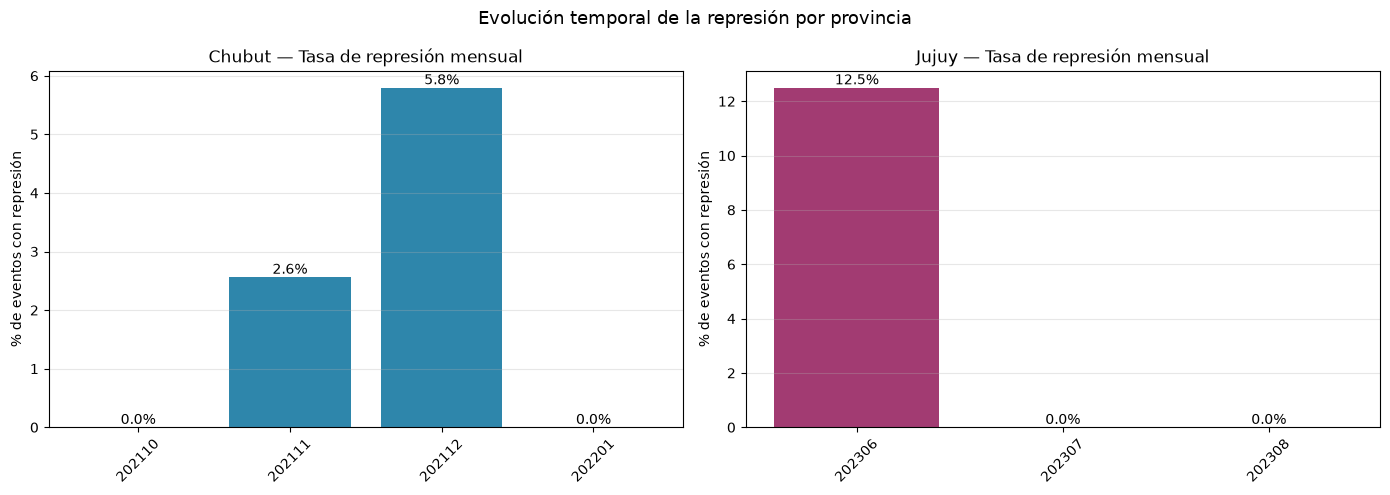

In [ ]:
print("=" * 70)
print("CRUCE: MES × INTERVENCIÓN ESTATAL")
print("=" * 70)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    print(f"\n=== {prov} ===")
    ct = pd.crosstab(sub["mes"], sub["intervencion_armonizada"])
    ct = ct.reindex(columns=[c for c in ["Ausencia", "Monitoreo", "Contención", "Disuasión", "Represión", "Sin datos"] if c in ct.columns], fill_value=0)
    print(ct.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chubut
ch_rep_mes = df_ch[df_ch["es_represion"] == 1].groupby("mes").size()
ch_total_mes = df_ch.groupby("mes").size()
ch_tasa_mes = (100 * ch_rep_mes / ch_total_mes).fillna(0)

axes[0].bar(ch_tasa_mes.index, ch_tasa_mes.values, color="#2E86AB")
axes[0].set_title("Chubut — Tasa de represión mensual")
axes[0].set_ylabel("% de eventos con represión")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", alpha=0.3)
for i, v in enumerate(ch_tasa_mes.values):
    axes[0].annotate(f"{v:.1f}%", (i, v), ha="center", va="bottom", fontsize=10)

# Jujuy
ju_rep_mes = df_j[df_j["es_represion"] == 1].groupby("mes").size()
ju_total_mes = df_j.groupby("mes").size()
ju_tasa_mes = (100 * ju_rep_mes / ju_total_mes).fillna(0)

axes[1].bar(ju_tasa_mes.index, ju_tasa_mes.values, color="#A23B72")
axes[1].set_title("Jujuy — Tasa de represión mensual")
axes[1].set_ylabel("% de eventos con represión")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)
for i, v in enumerate(ju_tasa_mes.values):
    axes[1].annotate(f"{v:.1f}%", (i, v), ha="center", va="bottom", fontsize=10)

plt.suptitle("Evolución temporal de la represión por provincia", fontsize=13)
plt.tight_layout()
plt.show()

 la distribución temporal de la represión muestra cómo se desplegó a lo largo del ciclo.

**Chubut**: la represión se concentra en diciembre de 2021 (4 eventos), con solo 1 en noviembre y 0 en enero. El pico represivo coincide con el pico del conflicto (21/12), lo que sugiere una represión **reactiva al estallido**, no una estrategia preventiva.

**Jujuy**: la represión se concentra fuertemente en junio de 2023 (5 eventos), con 2 casos de disuasión también en junio. Julio no registra represión. Esto indica que la respuesta represiva fue **inmediata al estallido del conflicto**, no una estrategia sostenida en el tiempo.

Sin embargo, la presencia de disuasión en junio en Jujuy agrega una dimensión preventiva que no existe en Chubut. La combinación de represión + disuasión en el mes de estallido sugiere una estrategia dual: castigar y desincentivar simultáneamente.

En ambos casos, los meses posteriores al pico muestran caída de la represión. La diferencia es que en Jujuy la caída es a cero, mientras que en Chubut sigue habiendo casos residuales en enero.

In [39]:
print("=" * 65)
print("HERIDOS Y DETENCIONES")
print("=" * 65)

for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    print(f"\n--- {prov} ---")
    heridos_validos = sub[sub["heridos"] != 99]["heridos"]
    detenciones_validas = sub[sub["detenciones"] != 99]["detenciones"]
    
    print(f"  Eventos con datos de heridos: {len(heridos_validos)}")
    
    print(f"  Eventos con datos de detenciones: {len(detenciones_validas)}")

HERIDOS Y DETENCIONES

--- Chubut ---
  Eventos con datos de heridos: 5
  Eventos con datos de detenciones: 4

--- Jujuy ---
  Eventos con datos de heridos: 26
  Eventos con datos de detenciones: 24


la cobertura de heridos y detenciones es profundamente desigual entre ambas provincias, y eso mismo es el hallazgo.

Jujuy tiene 26 eventos con datos sobre heridos y 24 con datos sobre detenciones. Chubut tiene apenas 5 y 4 respectivamente. La diferencia es de cinco a uno.

Esta brecha no puede leerse como "Jujuy tuvo más represión física que Chubut" porque el output solo informa eventos con datos disponibles, no eventos con víctimas confirmadas. Pero sí dice algo importante: **en Jujuy la represión fue un fenómeno lo suficientemente visible como para que los medios registraran sistemáticamente el conteo de heridos y detenidos. En Chubut, la mayoría de los eventos no tienen información sobre heridos o detenciones, lo cual sugiere que la represión física no fue el eje del conflicto**.

Es consistente con el resto del comparativo. Jujuy tuvo más disuasión, más represión, más judicialización y más cobertura de represión. Chubut tuvo menos de todo eso, y la desescalada política (derogación de la ley minera) hizo que la represión no fuera el tema central del conflicto.

En términos metodológicos, la cobertura diferencial es también un hallazgo en sí mismo: **el nivel de documentación de la represión es un indicador de su centralidad en el conflicto**. Cuando la represión es marginal, los medios no la registran con detalle; cuando es parte constitutiva del conflicto, la registran evento por evento.

Una diferencia que atraviesa varios cruces es la cobertura diferencial de la respuesta estatal. Chubut tiene 24.8% de eventos sin datos sobre intervención estatal; Jujuy tiene 19.7%. En escala, la diferencia es más marcada en detenciones y judicialización.

Esto no es un dato menor. En un contexto donde la represión es baja, la fuente periodística puede no cubrir la respuesta estatal porque no es noticia. En un contexto donde la represión es parte del conflicto, la cobertura se vuelve más sistemática.

La diferencia de cobertura refuerza la interpretación del comparativo: **la represión no es solo un fenómeno que se documenta más en Jujuy, es un fenómeno que efectivamente tiene más presencia en el conflicto jujeño**. La tasa ajustada por cobertura (5.5% Chubut vs 9.4% Jujuy) es la mejor expresión de este punto.

## Bloque 5 — Contexto del conflicto

Este bloque compara variables de contexto que no son ni repertorio ni respuesta estatal directa, pero que caracterizan la intensidad y el tono del conflicto: escala, intensidad, disrupción, amenaza política y resultado del episodio.

In [35]:
print("=" * 65)
print("ESCALA, INTENSIDAD Y DISRUPCIÓN")
print("=" * 65)

for col in ["escala", "intensidad", "disrupcion"]:
    print(f"\n=== {col} (% dentro de cada provincia) ===")
    ct = pd.crosstab(df["provincia"], df[col], normalize="index") * 100
    print(ct.round(1).to_string())

ESCALA, INTENSIDAD Y DISRUPCIÓN

=== escala (% dentro de cada provincia) ===
escala       99  alta  baja  media
provincia                         
Chubut     13.2   7.4  52.9   26.4
Jujuy       3.1  56.2  10.9   29.7

=== intensidad (% dentro de cada provincia) ===
intensidad    99  alta  baja  media  muy_alta  no aplica
provincia                                               
Chubut      12.4   7.4  27.3   52.1       0.0        0.8
Jujuy        4.6  47.7   7.7   36.9       3.1        0.0

=== disrupcion (% dentro de cada provincia) ===
disrupcion  0.0   1.0   99.0
provincia                   
Chubut      39.7  51.2   9.1
Jujuy       43.1  55.4   1.5


los dos conflictos operaron en registros distintos de intensidad.

**Escala**: Jujuy tuvo 55% de eventos con escala alta, mientras que Chubut tuvo predominancia de escala baja. El conflicto jujeño fue percibido y registrado como masivo; el chubutense como mayormente local.

**Intensidad**: Jujuy tuvo 47% de eventos con intensidad alta (más un 3% de "muy alta"). Chubut tuvo predominancia de intensidad media.

**Disrupción**: Jujuy tiene 55% de eventos disruptivos; Chubut 51%. La diferencia es menor, pero consistente con el mayor peso del corte en el repertorio jujeño.

El patrón sugiere que **Jujuy fue un conflicto de mayor intensidad y escala**, mientras que Chubut fue un conflicto de mayor volumen (más eventos) pero de menor intensidad por evento. Esto refuerza la idea de dos lógicas: Chubut como conflicto de "muchas protestas pequeñas" y Jujuy como conflicto de "pocas protestas grandes".

In [36]:
print("=" * 65)
print("AMENAZA POLÍTICA")
print("=" * 65)

ct_am = pd.crosstab(df["provincia"], df["amenaza_politica"], normalize="index") * 100
print(ct_am.round(1).to_string())

# Distribución absoluta
print("\n=== Conteo absoluto ===")
print(pd.crosstab(df["provincia"], df["amenaza_politica"]).to_string())

# Promedio (excluyendo 99)
print("\n=== Promedio (excluyendo sin datos) ===")
for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    sub_valid = sub[sub["amenaza_politica"] != 99]
    print(f"{prov}: {sub_valid['amenaza_politica'].mean():.2f} (n={len(sub_valid)})")

AMENAZA POLÍTICA
amenaza_politica  0.0   1.0   2.0   3.0   99.0
provincia                                     
Chubut            28.1  52.1   5.0   1.7  13.2
Jujuy             20.0  24.6  40.0   4.6  10.8

=== Conteo absoluto ===
amenaza_politica  0.0   1.0   2.0   3.0   99.0
provincia                                     
Chubut              34    63     6     2    16
Jujuy               13    16    26     3     7

=== Promedio (excluyendo sin datos) ===
Chubut: 0.77 (n=105)
Jujuy: 1.33 (n=59)


El nivel de amenaza política es sustantivamente distinto.

**Chubut** tiene predominancia del nivel 1 (amenaza baja): la mayoría de los eventos operaron en un contexto de tensión política baja o nula. Solo un pequeño porcentaje alcanza niveles medios o altos.

**Jujuy** tiene predominancia del nivel 2 (amenaza media): la mayoría de los eventos operaron en un contexto de tensión política considerable. Esto es coherente con la confrontación abierta entre el gobierno provincial y los manifestantes.

El promedio confirma la diferencia: Chubut tiene un promedio más cercano a 1, Jujuy más cercano a 2.

Esta diferencia es un indicador del **clima político general** en el que se desarrolló cada conflicto. En Chubut el conflicto se desarrolló contra un gobierno que, aunque resistente inicialmente, terminó cediendo; en Jujuy el conflicto se desarrolló contra un gobierno que mantuvo la posición de confrontación a lo largo de todo el período.

In [30]:
print("=" * 65)
print("RESULTADO DEL EPISODIO")
print("=" * 65)

ct_res = pd.crosstab(df["provincia"], df["resultado_episodio"], normalize="index") * 100
print(ct_res.round(1).to_string())

print("\n=== Conteo absoluto ===")
print(pd.crosstab(df["provincia"], df["resultado_episodio"]).to_string())

# Eventos con resultado positivo
print("\n=== Eventos con resultado positivo (1, 2 o 3) ===")
for prov, sub in [("Chubut", df_ch), ("Jujuy", df_j)]:
    n_pos = sub["resultado_episodio"].isin([1, 2, 3]).sum()
    pct_pos = 100 * n_pos / len(sub)
    print(f"{prov}: {n_pos} eventos ({pct_pos:.1f}%)")

RESULTADO DEL EPISODIO
resultado_episodio  0.0   1.0   2.0   3.0   99.0
provincia                                       
Chubut              71.1  12.4   0.8   0.8  14.9
Jujuy               82.3  12.9   3.2   1.6   0.0

=== Conteo absoluto ===
resultado_episodio  0.0   1.0   2.0   3.0   99.0
provincia                                       
Chubut                86    15     1     1    18
Jujuy                 51     8     2     1     0

=== Eventos con resultado positivo (1, 2 o 3) ===
Chubut: 17 eventos (14.0%)
Jujuy: 11 eventos (16.7%)


En ambos casos, la mayoría de los eventos no tienen un resultado registrado.

Sin embargo, la proporción de eventos con resultado positivo es mayor en Jujuy (17%) que en Chubut (14%), aunque por un margen estrecho.

El dato más interpretativo es lo que **no aparece**: en ambos casos, la ausencia de resultado en la mayoría de los eventos puede reflejar dos cosas distintas. O bien la mayoría de las protestas no obtuvieron respuesta estatal, o bien la fuente periodística no cubrió los desenlaces.

En el caso de Chubut, el resultado más relevante del período (la derogación de la Ley de Zonificación Minera) probablemente no aparece codificado como resultado de ningún evento puntual: fue un resultado agregado del ciclo completo. Lo mismo aplica a Jujuy: el resultado principal (la suspensión parcial de algunos artículos de la reforma) es un resultado agregado, no de un evento.

**Advertencia**: la variable "resultado_episodio" es útil para captar resultados puntuales (una reunión, una respuesta oficial), pero subestima los resultados estructurales del ciclo completo.

## Bloque 6 — Hallazgos transversales

Los hallazgos que emergen de los bloques anteriores se pueden sintetizar en seis puntos que articulan el comparativo completo.

### 1. Dos formas opuestas de gestionar el conflicto

Si hay algo que deja el comparativo es que Chubut y Jujuy hicieron cosas muy distintas frente a la protesta.

En Chubut, cuando el conflicto llegó a su pico en diciembre de 2021, el gobierno terminó derogando la ley minera. La represión fue baja (4.1%) y más bien reactiva. El conflicto se desactivó por concesión: el Estado cedió y las aguas se calmaron.

En Jujuy fue al revés. El gobierno sostuvo la reforma constitucional y desplegó una estrategia más activa, que combinó contención, disuasión y represión focalizada. La represión fue más alta (7.6%) y además apareció la disuasión, una categoría que directamente no existe en el caso chubutense.

Son dos formas de pararse frente al conflicto. Ninguna es "mejor" en términos analíticos, pero producen ciclos de protesta con formas temporales muy distintas.

### 2. El corte de ruta como objeto de disputa

El corte de ruta es el repertorio más castigado en las dos provincias, pero con una diferencia que no es menor: en Jujuy se reprimió el 28.6% de los cortes, en Chubut apenas el 7.7%.

La explicación no es solo represiva. En Jujuy el corte era justamente la práctica que la reforma constitucional buscaba penalizar. El Estado tenía un motivo explícito para reprimirlo y la represión funcionaba como aplicación de la norma. En Chubut el corte era una táctica más dentro de un repertorio amplio, sin estatus de "objeto de política pública". Nadie había hecho una ley contra el corte.

Un detalle que refuerza esto: los paros no reciben represión en ninguna de las dos provincias. Ni un caso. El Estado discrimina entre repertorios: tolera el paro pero castiga el corte.

### 3. La densidad del evento como indicador de articulación

Los eventos de Jujuy son más densos que los de Chubut. Esto se ve en tres dimensiones:

- Promedio de demandas por evento: 1.48 en Jujuy vs 0.95 en Chubut
- Promedio de actores por evento: también más alto en Jujuy
- Promedio de tipos de acción por evento: también más alto en Jujuy

Un evento chubutense típico es convocado por un actor específico con una demanda específica. Un evento jujeño típico articula varios actores, varias demandas y varios repertorios en un mismo episodio.

Esto no es un detalle menor. Sugiere dos formas distintas de organización del conflicto: Chubut como suma de focos locales, Jujuy como coordinación entre sectores organizados.

### 4. La represión en Jujuy fue selectiva

En Jujuy, el actor más movilizado fue docentes (62% de los eventos). Pero el actor más reprimido fue comunidades indígenas (27.8% de sus eventos tuvieron represión), seguido por organizaciones sociales (15%). Los docentes, con toda su presencia, apenas llegaron al 7.3%.

Es un dato incómodo. La represión no cayó sobre quien más se movilizó sino sobre quien tenía menos capacidad de defensa legal o mediática. Las comunidades indígenas son actores con menos acceso a abogados, menos presencia en medios nacionales y menos respaldo institucional. Y fueron proporcionalmente las más castigadas.

### 5. La paradoja de Chubut: mucha protesta, poca represión

Chubut tuvo casi el doble de eventos que Jujuy (121 vs 66). Y sin embargo tuvo menos represión proporcional (4.1% vs 7.6%).

A primera vista parece contradictorio: más conflicto debería traer más represión. Pero no es así, y el comparativo lo muestra. La explicación está en la estrategia estatal: ante la magnitud del conflicto minero, el gobierno provincial optó por ceder antes que reprimir. La baja represión no fue debilidad, fue una elección.

Esto rompe con una intuición bastante extendida en los estudios sobre represión: que a mayor conflictividad le corresponde mayor represión. Los dos casos muestran que no siempre es así.